# Boston 311 Crew Planner

## How we used AI

_To be filled in at BOS-7: a short paragraph and a table of each section's AI involvement._

## 0. Setup

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pulp
from dotenv import load_dotenv
from langchain_community.cache import SQLiteCache
from langchain_core.globals import set_llm_cache

# Find the repo root so the notebook works whether Jupyter starts in notebooks/ or the repo root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load_dotenv(ROOT / ".env")

RAW, PROCESSED, CACHE = ROOT / "data/raw", ROOT / "data/processed", ROOT / "data/cache"
for d in (RAW, PROCESSED, CACHE):
    d.mkdir(parents=True, exist_ok=True)

# The brief's facts
DEPTS = {
    "PWDx": {"name": "Public Works", "per_crew_day": 12, "annual_cost": 130_000, "jan_crews": 50},
    "BTDT": {"name": "Transportation", "per_crew_day": 15, "annual_cost": 110_000, "jan_crews": 18},
    "PARK": {"name": "Parks & Recreation", "per_crew_day": 6, "annual_cost": 120_000, "jan_crews": 10},
    "ISD": {"name": "Inspectional Services", "per_crew_day": 4, "annual_cost": 140_000, "jan_crews": 16},
}
WORK_DAYS = 21
RELEASE_FEE = 0.25  # share of annual cost
SEASONAL_MULT = 1.3  # Parks seasonal crews, times monthly cost
SEASONAL_MONTHS = range(4, 11)  # April to October
OVERDUE_PENALTY = 20
LATE_30_PENALTY = 100  # extra, for a request still open 30 days past its target

LLM_MODEL = os.getenv("LLM_MODEL", "openai/gpt-oss-20b")
set_llm_cache(SQLiteCache(database_path=str(CACHE / "llm_cache.db")))

print(pd.DataFrame({code: {"name": d["name"], "monthly capacity": f"{d['jan_crews'] * d['per_crew_day'] * WORK_DAYS:,}"}
                    for code, d in DEPTS.items()}).T)
print("GROQ_API_KEY set:", bool(os.getenv("GROQ_API_KEY")))
print("LLM_MODEL:", LLM_MODEL)

/var/folders/7n/hl0bm63x61x2mgmjq9c36_m80000gn/T/ipykernel_87417/704908881.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.cache import SQLiteCache


                       name monthly capacity
PWDx           Public Works           12,600
BTDT         Transportation            5,670
PARK     Parks & Recreation            1,260
ISD   Inspectional Services            1,344
GROQ_API_KEY set: False
LLM_MODEL: openai/gpt-oss-20b


## 1. Data

311 requests opened in 2023 and 2024, from Analyze Boston. `request_types.csv` keeps every department and queue a type was sent to in 2024, across all departments; everything after it uses only the four departments in the brief.

In [2]:
import html
import shutil
import urllib.request

URL = "https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource/{}/download/lagan_311_open_data_{}_rvsd3.csv"
FILES = {2023: "e6013a93-1321-4f2a-bf91-8d8a02f1e62f", 2024: "dff4d804-5031-443a-8409-8344efd0e5c8"}

# data.boston.gov redirects to a signed S3 URL with an explicit ":443"; urllib keeps the port in the Host header, which breaks the signature (HTTP 403)
class StripPort(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        return super().redirect_request(req, fp, code, msg, headers, newurl.replace(":443/", "/"))

for year, resource in FILES.items():
    path = RAW / f"311_{year}.csv"
    if not path.exists():
        with urllib.request.build_opener(StripPort).open(URL.format(resource, year)) as r, open(path, "wb") as f:
            shutil.copyfileobj(r, f)

con = duckdb.connect()
con.sql(f"create view raw as select * from read_csv_auto({[str(RAW / f'311_{y}.csv') for y in FILES]})")
con.sql("select year(open_dt) as year, count(*) as requests from raw group by 1 order by 1").df()

,year,requests
0,2023,307791
1,2024,306756


In [3]:
types = con.sql("""
    select department as dept, type, queue, count(*) as n_2024
    from raw where year(open_dt) = 2024
    group by all order by type, n_2024 desc, dept, queue
""").df()
types.to_csv(PROCESSED / "request_types.csv", index=False)
print(f"{len(types):,} dept/type/queue rows, {types['type'].nunique()} request types")

2,208 dept/type/queue rows, 170 request types


In [4]:
df = con.sql(f"select * from raw where department in {tuple(DEPTS)}").df()

brief = pd.Series({"PWDx": 157_610, "BTDT": 81_447, "PARK": 18_736, "ISD": 18_624})
counts = df[df.open_dt.dt.year == 2024].department.value_counts()
print(pd.DataFrame({"2024 requests": counts, "brief": brief}))
assert counts.equals(brief.reindex(counts.index))

# Shares are over all 2024 requests, as in the brief
print(con.sql("""
    select round(100 * avg((sla_target_dt is null)::int), 1) as pct_no_target,
           round(100 * avg((source = 'Employee Generated')::int), 1) as pct_employee
    from raw where year(open_dt) = 2024
""").df().to_string(index=False))

titles = df.case_title.fillna("")
print("titles changed by html.unescape:", (titles.map(html.unescape) != titles).sum())
df["case_title"] = df.case_title.map(html.unescape, na_action="ignore")

      2024 requests   brief
PWDx         157610  157610
BTDT          81447   81447
PARK          18736   18736
ISD           18624   18624


 pct_no_target  pct_employee
          15.9          42.2
titles changed by html.unescape: 0


In [5]:
monthly = (df.assign(month=df.open_dt.dt.strftime("%Y-%m"))
           .groupby(["department", "month"]).size().rename("requests")
           .reset_index().rename(columns={"department": "dept"}))
monthly.to_csv(PROCESSED / "monthly_demand.csv", index=False)
monthly.pivot(index="month", columns="dept", values="requests")

dept,BTDT,ISD,PARK,PWDx
month,,,,
2023-01,5692,1307,765,12843
2023-02,5316,1793,651,9978
2023-03,6889,1240,911,12402
2023-04,6143,1201,1206,12985
2023-05,6737,1386,2095,15267
2023-06,6682,1723,2313,14947
2023-07,5517,1587,2299,16188
2023-08,6473,1723,2382,20224
2023-09,7190,1678,1532,18578


## 2. Exploratory analysis

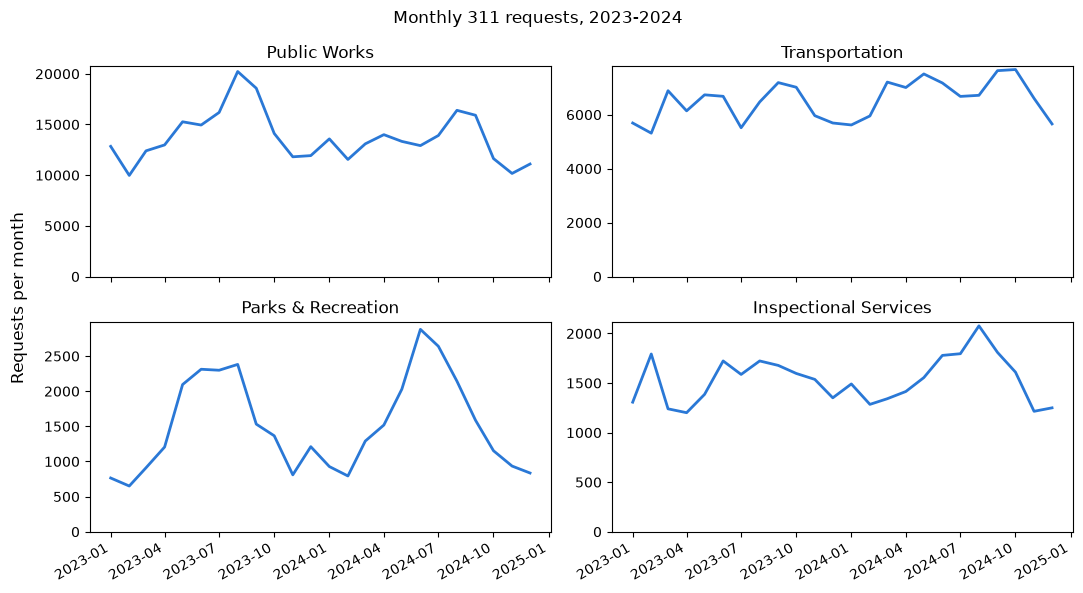

In [6]:
BLUE, GRAY = "#2a78d6", "#888888"

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (code, d) in zip(axes.flat, DEPTS.items()):
    m = monthly[monthly.dept == code]
    ax.plot(pd.to_datetime(m.month), m.requests, color=BLUE, lw=2)
    ax.set_title(d["name"])
    ax.set_ylim(bottom=0)
fig.supylabel("Requests per month")
fig.suptitle("Monthly 311 requests, 2023-2024")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

Parks is the most seasonal: its June 2024 peak (2,881) is 3.6 times its February low (794), while Transportation stays between about 5,300 and 7,700 a month.

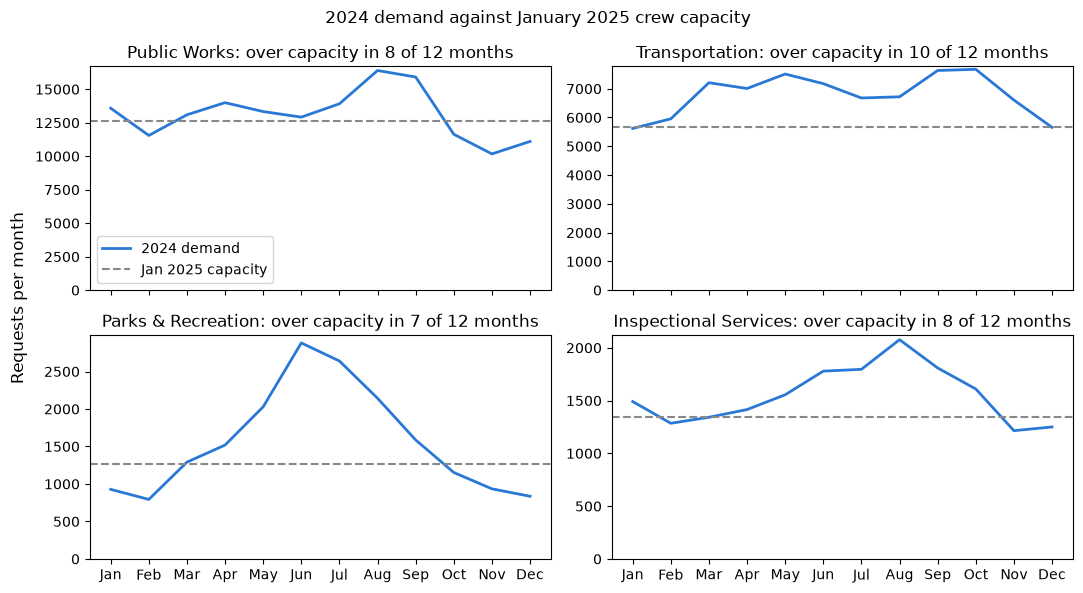

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (code, d) in zip(axes.flat, DEPTS.items()):
    m = monthly[(monthly.dept == code) & monthly.month.str.startswith("2024")]
    cap = d["jan_crews"] * d["per_crew_day"] * WORK_DAYS
    months = pd.to_datetime(m.month).dt.strftime("%b")
    ax.plot(months, m.requests, color=BLUE, lw=2, label="2024 demand")
    ax.axhline(cap, color=GRAY, ls="--", lw=1.5, label="Jan 2025 capacity")
    ax.set_title(f"{d['name']}: over capacity in {(m.requests > cap).sum()} of 12 months")
    ax.set_ylim(bottom=0)
axes[0, 0].legend()
fig.supylabel("Requests per month")
fig.suptitle("2024 demand against January 2025 crew capacity")
fig.tight_layout()
plt.show()

At January 2025 crew levels, every department would have fallen short in most months of 2024, and Transportation in 10 of 12.

year    2023    2024  growth
dept                        
BTDT   75314   81447   0.081
ISD    18123   18624   0.028
PARK   17541   18736   0.068
PWDx  171268  157610  -0.080


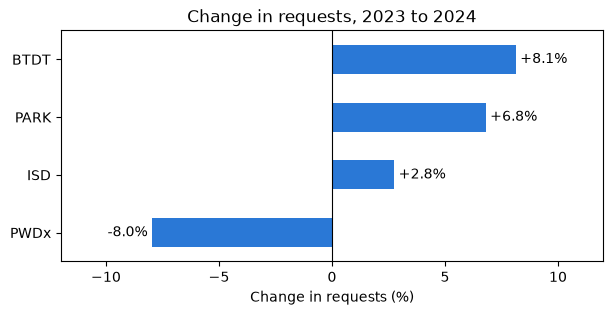

In [8]:
totals = monthly.assign(year=monthly.month.str[:4]).pivot_table(index="dept", columns="year", values="requests", aggfunc="sum")
totals["growth"] = totals["2024"] / totals["2023"] - 1
print(totals.round(3))

ax = totals.growth.sort_values().mul(100).plot.barh(color=BLUE, figsize=(7, 3))
ax.bar_label(ax.containers[0], fmt="%+.1f%%", padding=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-12, 12)
ax.set(xlabel="Change in requests (%)", ylabel="", title="Change in requests, 2023 to 2024")
plt.show()

Transportation, Parks and Inspectional Services grew from 2023 to 2024, but Public Works fell 8.0%, so the forecast's growth term lowers Public Works for 2025.

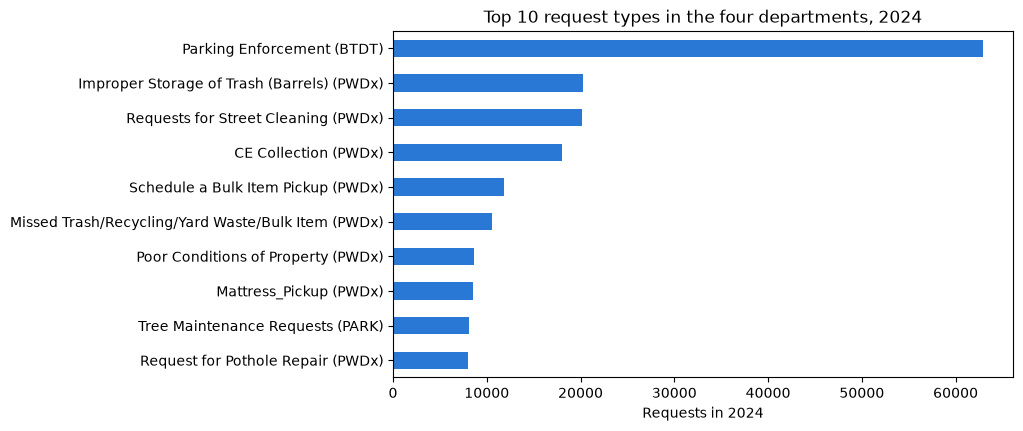

In [9]:
top = df[df.open_dt.dt.year == 2024].groupby(["type", "department"]).size().nlargest(10).sort_values()
ax = top.plot.barh(color=BLUE, figsize=(8, 4.5))
ax.set_yticklabels([f"{t} ({d})" for t, d in top.index])
ax.set(xlabel="Requests in 2024", ylabel="", title="Top 10 request types in the four departments, 2024")
plt.show()

Parking Enforcement alone is 62,973 requests, 77% of Transportation's 2024 volume; Public Works' load is spread across sanitation and street-cleaning types.

## 3. 2025 demand forecast and backtest

Each 2025 month is the average 2023-2024 seasonal shape × the 2024 monthly level × the 2023→2024 growth. The backtest predicts 2024 from 2023 alone (2023 shape × 2023 level, no growth term), because we don't have 2022 data.

In [10]:
m = monthly.assign(year=monthly.month.str[:4], mo=monthly.month.str[5:])
m["seasonal"] = m.requests / m.groupby(["dept", "year"]).requests.transform("mean")
m23, m24 = m[m.year == "2023"], m[m.year == "2024"]

bt = m24.merge(m23[["dept", "mo", "seasonal"]], on=["dept", "mo"], suffixes=("", "_2023"))
bt["pred"] = bt.seasonal_2023 * bt.dept.map(m23.groupby("dept").requests.mean())
mape = (abs(bt.pred - bt.requests) / bt.requests).groupby(bt.dept).mean().mul(100).round(1)
print("Backtest MAPE (%), predicting 2024 from 2023:")
print(mape.to_string())

Backtest MAPE (%), predicting 2024 from 2023:
dept
BTDT     7.6
ISD     13.3
PARK    17.7
PWDx    13.6


In [11]:
fc = m.groupby(["dept", "mo"], as_index=False).seasonal.mean()
fc["forecast"] = (fc.seasonal * fc.dept.map(m24.groupby("dept").requests.mean()) * fc.dept.map(1 + totals.growth)).round().astype(int)
fc["month"] = "2025-" + fc.mo
fc[["dept", "month", "forecast"]].to_csv(PROCESSED / "forecast_2025.csv", index=False)

print(pd.DataFrame({"2024 actual": totals["2024"], "2025 forecast": fc.groupby("dept").forecast.sum()}))
fc.pivot(index="month", columns="dept", values="forecast")

      2024 actual  2025 forecast
dept                            
BTDT        81447          88078
ISD         18624          19140
PARK        18736          20010
PWDx       157610         145040


dept,BTDT,ISD,PARK,PWDx
month,,,,
2025-01,6367,1456,932,11688
2025-02,6328,1607,795,9539
2025-03,7926,1344,1209,11275
2025-04,7381,1361,1499,11939
2025-05,8001,1531,2279,12599
2025-06,7787,1824,2858,12273
2025-07,6837,1761,2721,13257
2025-08,7418,1977,2503,16109
2025-09,8332,1816,1721,15188


The backtest is off by 7.6% a month on average for Transportation and 17.7% for Parks, which was flat from May to August in 2023 but peaked sharply in June 2024. Public Works is forecast at 145,040 requests in 2025, 8.0% below 2024, because the method carries its 2023 to 2024 drop forward; the other three departments grow by 2.8% to 8.1%.

## 4. Staffing plan (MILP) and the hold-flat baseline

## 5. Sensitivity: demand ±20%, snowstorm, heat wave

## 6. 311 intake assistant and its accuracy

## 7. Planner agent with 5 tools

## 8. Gradio app

## 9. Other considerations: neighborhood equity, resident versus employee requests

2024 requests only. The on-time rate uses the city's `on_time` flag over all requests, so a request with no target date counts as on time; median days to close is over closed requests. Duplicate neighborhood spellings are merged, the 1,899 requests with no neighborhood are dropped, and "Boston" means no specific neighborhood was given.

In [12]:
import numpy as np

merge = {"South Boston": "South Boston / South Boston Waterfront", "Allston": "Allston / Brighton",
         "Brighton": "Allston / Brighton", "Mattapan": "Greater Mattapan"}
d24 = df[(df.open_dt.dt.year == 2024) & df.neighborhood.notna()].copy()
d24["neighborhood"] = d24.neighborhood.replace(merge)
d24["ontime"] = d24.on_time == "ONTIME"
d24["days"] = (d24.closed_dt - d24.open_dt).dt.total_seconds() / 86400

stats = (d24.groupby(["department", "type", "neighborhood"])
         .agg(requests=("ontime", "size"), on_time_rate=("ontime", "mean"), median_days=("days", "median"))
         .round({"on_time_rate": 3, "median_days": 2}).reset_index().rename(columns={"department": "dept"}))
stats.to_csv(PROCESSED / "neighborhood_stats.csv", index=False)
print(f"{len(stats):,} dept/type/neighborhood rows, {stats.neighborhood.nunique()} neighborhoods")

2,947 dept/type/neighborhood rows, 19 neighborhoods


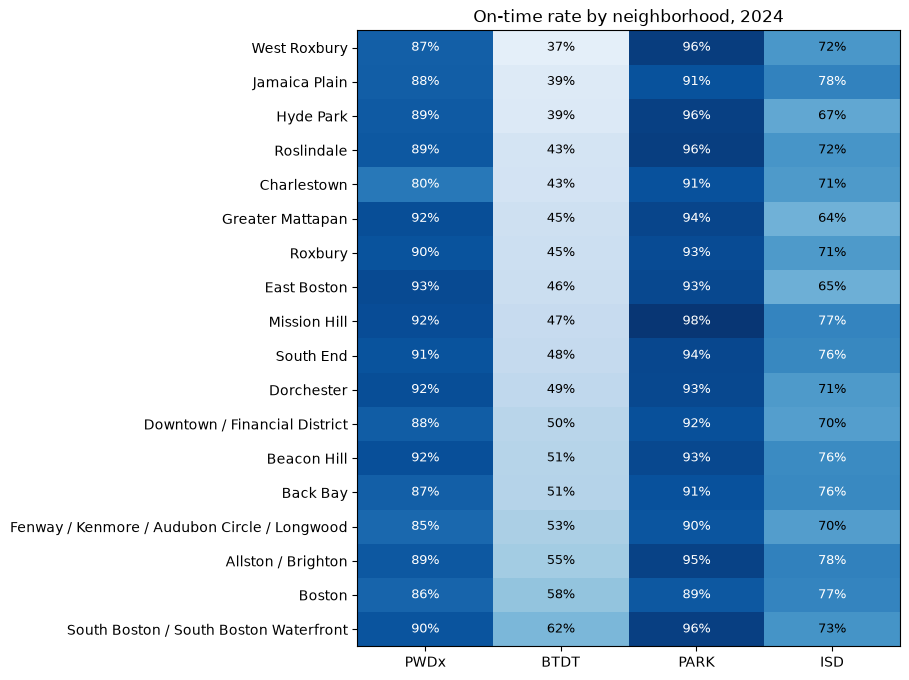

department
PWDx    12.2
BTDT    25.5
PARK     9.0
ISD     14.1


In [13]:
rate = d24.pivot_table(index="neighborhood", columns="department", values="ontime", aggfunc="mean")[list(DEPTS)]
# Chestnut Hill has only 12 requests, too few for a rate
counts = d24.pivot_table(index="neighborhood", columns="department", values="ontime", aggfunc="size")
rate = rate[counts.min(axis=1) >= 100].sort_values("BTDT")

fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(rate, cmap="Blues", vmin=0.3, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(rate.values):
    ax.text(c, r, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.75 else "black", fontsize=9)
ax.set_xticks(range(4), rate.columns)
ax.set_yticks(range(len(rate)), rate.index)
ax.set_title("On-time rate by neighborhood, 2024")
plt.show()
print((rate.max() - rate.min()).mul(100).round(1).rename("gap between best and worst neighborhood (points)").to_string())

Transportation has the widest gap between neighborhoods, from 37% on time in West Roxbury to 62% in South Boston; Inspectional Services is lowest in Greater Mattapan (64%) and East Boston (65%).

In [14]:
d24["requester"] = np.where(d24.source.isin(["Employee Generated", "City Worker App"]), "employee", "resident")
d24.groupby(["department", "requester"]).agg(
    requests=("ontime", "size"), on_time_rate=("ontime", "mean"), median_days=("days", "median")
).round(2).unstack("requester").loc[list(DEPTS)]

requests          on_time_rate          median_days         
requester  employee resident     employee resident    employee resident
department                                                             
PWDx          78039    79039         0.90     0.90        0.12     0.53
BTDT          50019    30890         0.50     0.50        0.88     1.56
PARK          10825     7112         0.95     0.91        2.83     1.90
ISD            7485    11109         0.75     0.71        2.25     3.25

On-time rates for resident and employee requests are within 4 points in every department, but employee requests close faster in Public Works (median 0.12 against 0.53 days) and Transportation (0.88 against 1.56); Parks is the exception. Employee here means Employee Generated plus City Worker App, a wider group than the 42% in Section 1.

## 10. Analysis and limitations